Coefficients: [ 5.12990128 -0.57304885 -0.00956044]
MAE : 1.5488128280669662
MSE : 3.4796967164577475
RMSE: 1.8653945203247884
R2  : 0.9084812608021937


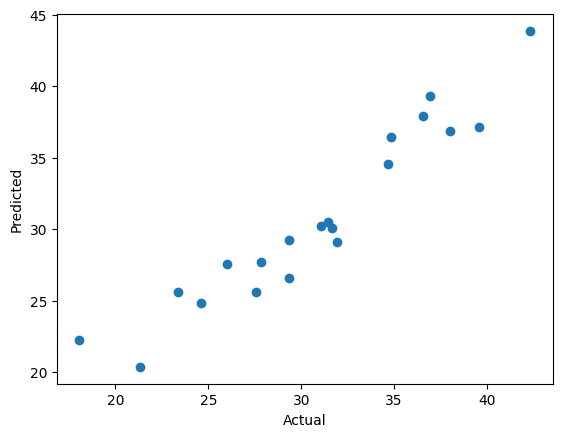

In [1]:
# Linear Regression: predicts house price (MEDV) from features. R2 close to 1 = good fit.
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Dataset hint: make 3 random feature columns (RM, LSTAT, TAX). Then build the price MEDV as a formula of those columns plus a little random noise.

np.random.seed(1)
n = 100
df = pd.DataFrame({"RM": np.random.uniform(4, 9, n),
                   "LSTAT": np.random.uniform(2, 30, n),
                   "TAX": np.random.randint(200, 700, n)})
df["MEDV"] = 5*df.RM - 0.6*df.LSTAT - 0.01*df.TAX + 10 + np.random.normal(0, 2, n)

X = df.drop("MEDV", axis=1)
y = df["MEDV"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Coefficients:", model.coef_)
print("MAE :", mean_absolute_error(y_test, pred))
print("MSE :", mean_squared_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2  :", r2_score(y_test, pred))

plt.scatter(y_test, pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()